##Brain-Tumor-Segmentation-UNET

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import glob
import cv2
from PIL import Image
import gc
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim

from sklearn.model_selection import GroupShuffleSplit

import albumentations
from albumentations.pytorch import ToTensorV2


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!cp /content/drive/MyDrive/Data_HW2_tumor_segmentation_DNN/kaggle_3m.zip /content/

# Unzip the file
!unzip -q /content/kaggle_3m.zip -d /content/

# Remove the ZIP file
!rm /content/kaggle_3m.zip

replace /content/kaggle_3m/data.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [35]:
!ls -lh /content/drive/MyDrive/Data_HW2_tumor_segmentation_DNN/kaggle_3m.zip

!rsync -ah --progress /content/drive/MyDrive/Data_HW2_tumor_segmentation_DNN/kaggle_3m.zip /content/

!unzip -oq /content/kaggle_3m.zip -d /content/

!rm -f /content/kaggle_3m.zip

print("Done! Folders extracted:", len(os.listdir('/content/kaggle_3m')))

-rw------- 1 root root 350M Nov 18 10:05 /content/drive/MyDrive/Data_HW2_tumor_segmentation_DNN/kaggle_3m.zip
sending incremental file list
kaggle_3m.zip
        366.40M 100%   51.46MB/s    0:00:06 (xfr#1, to-chk=0/1)
Done! Folders extracted: 112


In [36]:
import glob
import os
from pathlib import Path

# Dataset directory
dataset_dir = Path('/content/kaggle_3m')

# Find all TIFF files recursively
all_files = list(dataset_dir.rglob('*.tif'))

# Separate MRI images and segmentation masks
image_dict = {}
mask_dict = {}

for file in all_files:

    if file.stem.endswith('_mask'):
        # Remove "_mask" to obtain the corresponding image filename
        image_name = file.stem[:-5]
        key = (file.parent, image_name)
        mask_dict[key] = str(file)

    else:
        key = (file.parent, file.stem)
        image_dict[key] = str(file)

# Find filenames that have BOTH an image and a mask
common_keys = set(image_dict.keys()) & set(mask_dict.keys())

# Sort by patient folder and numerical slice number
def sort_key(key):
    folder, filename = key
    patient_id, slice_number = filename.rsplit('_', 1)
    return (folder.name, int(slice_number))

common_keys = sorted(common_keys, key=sort_key)

# Create matched image and mask lists
images = [image_dict[key] for key in common_keys]
masks = [mask_dict[key] for key in common_keys]

# Identify unmatched files
missing_masks = set(image_dict.keys()) - set(mask_dict.keys())
missing_images = set(mask_dict.keys()) - set(image_dict.keys())

# Extract image IDs
IDs = [Path(img).stem for img in images]

# Check the results
print("Total TIFF files:", len(all_files))
print("Matched image-mask pairs:", len(images))
print("Images without masks:", len(missing_masks))
print("Masks without images:", len(missing_images))

print("\nFirst 5 matched pairs:")
for img, mask in list(zip(images, masks))[:5]:
    print("Image:", os.path.basename(img))
    print("Mask: ", os.path.basename(mask))
    print()

# Verify matching
assert len(images) == len(masks)
assert all(
    Path(img).stem == Path(mask).stem[:-5]
    for img, mask in zip(images, masks)
)

print("Image-mask matching verification passed!")

Total TIFF files: 7858
Matched image-mask pairs: 3929
Images without masks: 0
Masks without images: 0

First 5 matched pairs:
Image: TCGA_CS_4941_19960909_1.tif
Mask:  TCGA_CS_4941_19960909_1_mask.tif

Image: TCGA_CS_4941_19960909_2.tif
Mask:  TCGA_CS_4941_19960909_2_mask.tif

Image: TCGA_CS_4941_19960909_3.tif
Mask:  TCGA_CS_4941_19960909_3_mask.tif

Image: TCGA_CS_4941_19960909_4.tif
Mask:  TCGA_CS_4941_19960909_4_mask.tif

Image: TCGA_CS_4941_19960909_5.tif
Mask:  TCGA_CS_4941_19960909_5_mask.tif

Image-mask matching verification passed!


In [37]:
# Create image and mask path lists
image_path = images.copy()
mask_path = masks.copy()

# Verify the paths
print("Number of images:", len(image_path))
print("Number of masks:", len(mask_path))

print("\nFirst image path:")
print(image_path[0])

print("\nFirst mask path:")
print(mask_path[0])

# Verify image-mask correspondence
assert len(image_path) == len(mask_path)

for img, mask in zip(image_path, mask_path):
    assert os.path.basename(img).replace('.tif', '') == \
           os.path.basename(mask).replace('_mask.tif', '')

print("\nAll image-mask pairs are correctly matched!")

Number of images: 3929
Number of masks: 3929

First image path:
/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1.tif

First mask path:
/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1_mask.tif

All image-mask pairs are correctly matched!


In [38]:
# Make a dataframe from the images and  masks
data_df = pd.DataFrame({'ID': IDs , 'image_path':images , 'mask_path':masks})
data_df


,ID,image_path,mask_path
0,TCGA_CS_4941_19960909_1,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...
1,TCGA_CS_4941_19960909_2,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...
2,TCGA_CS_4941_19960909_3,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...
3,TCGA_CS_4941_19960909_4,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...
4,TCGA_CS_4941_19960909_5,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...
...,...,...,...
3924,TCGA_HT_A61B_19991127_84,/content/kaggle_3m/TCGA_HT_A61B_19991127/TCGA_...,/content/kaggle_3m/TCGA_HT_A61B_19991127/TCGA_...
3925,TCGA_HT_A61B_19991127_85,/content/kaggle_3m/TCGA_HT_A61B_19991127/TCGA_...,/content/kaggle_3m/TCGA_HT_A61B_19991127/TCGA_...
3926,TCGA_HT_A61B_19991127_86,/content/kaggle_3m/TCGA_HT_A61B_19991127/TCGA_...,/content/kaggle_3m/TCGA_HT_A61B_19991127/TCGA_...
3927,TCGA_HT_A61B_19991127_87,/content/kaggle_3m/TCGA_HT_A61B_19991127/TCGA_...,/content/kaggle_3m/TCGA_HT_A61B_19991127/TCGA_...


In [39]:
# find tumors
def find_Tumors(mask_path):
    mask = Image.open(mask_path)
    mask_max = np.max(mask)
    if mask_max > 0:
       return 1
    else:
       return 0

In [40]:
print(len(list(data_df["mask_path"])))
mask_path_list = list(data_df["mask_path"])
tumors_list = [find_Tumors(path) for path in mask_path_list]

3929


In [41]:
print(len(tumors_list))
print(tumors_list[20:50])

data_df["Tumor"] = tumors_list
del tumors_list
gc.collect()

3929
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


21036

In [42]:
data_df['Tumor'].value_counts()

,count
Tumor,
0,2556
1,1373


In [43]:
data_df.head(5)

,ID,image_path,mask_path,Tumor
0,TCGA_CS_4941_19960909_1,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,0
1,TCGA_CS_4941_19960909_2,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,0
2,TCGA_CS_4941_19960909_3,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,0
3,TCGA_CS_4941_19960909_4,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,0
4,TCGA_CS_4941_19960909_5,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,/content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_...,0


Image path: /content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_15.tif
Mask path: /content/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_15_mask.tif


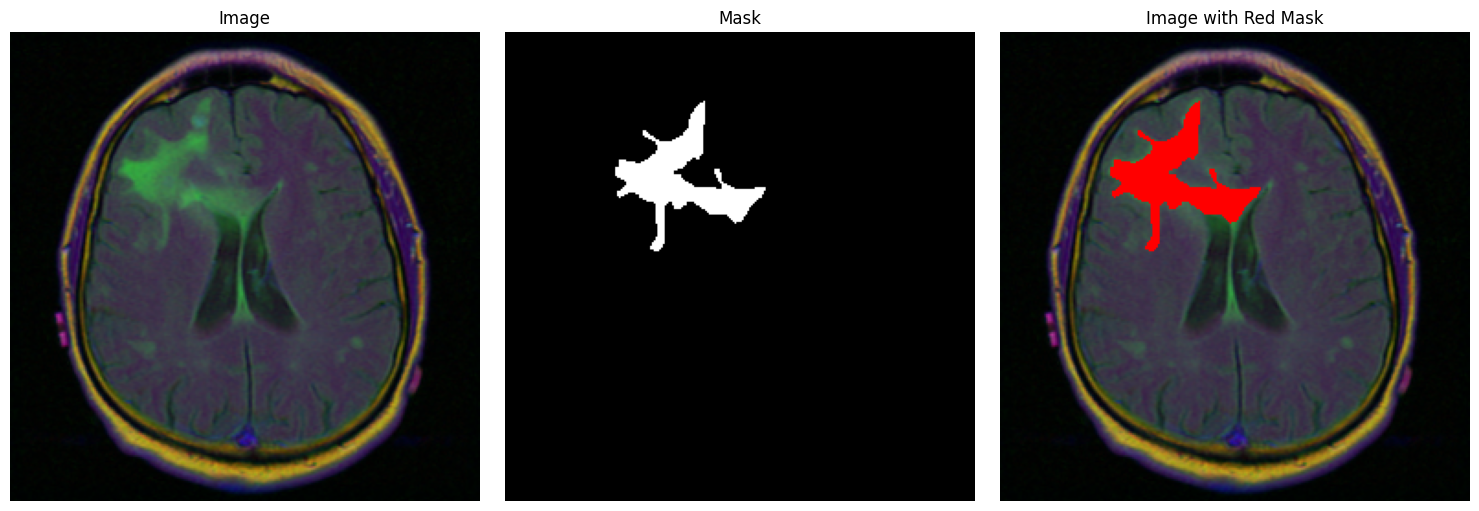

6639

In [44]:
# Select an image and its mask
index = 14

name_im = image_path[index]
name = mask_path[index]

print("Image path:", name_im)
print("Mask path:", name)

# Read image and mask
img_org = cv2.imread(name_im, cv2.IMREAD_COLOR)
mask_org = cv2.imread(name, cv2.IMREAD_GRAYSCALE)

# Check whether files were loaded successfully
assert img_org is not None, f"Could not read image: {name_im}"
assert mask_org is not None, f"Could not read mask: {name}"

plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img_org, cv2.COLOR_BGR2RGB))
plt.title('Image')
plt.axis('off')

# Original mask
plt.subplot(1, 3, 2)
plt.imshow(mask_org, cmap='gray')
plt.title('Mask')
plt.axis('off')

# Apply red mask to image
red_image = img_org.copy()
red_image[mask_org == 255] = [0, 0, 255]  # Red in OpenCV BGR format

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(red_image, cv2.COLOR_BGR2RGB))
plt.title('Image with Red Mask')
plt.axis('off')

plt.tight_layout()
plt.show()

del img_org, mask_org, red_image
gc.collect()

In [45]:
def plot_with_mask(path_img, path_mask):

    # Read image and mask
    img_org = cv2.imread(path_img, cv2.IMREAD_COLOR)
    mask_org = cv2.imread(path_mask, cv2.IMREAD_GRAYSCALE)

    if img_org is None:
        raise ValueError(f"Could not read image: {path_img}")

    if mask_org is None:
        raise ValueError(f"Could not read mask: {path_mask}")

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img_org, cv2.COLOR_BGR2RGB)

    # Create a copy of the original image
    red_image = img_rgb.copy()

    # Apply red color to tumor regions
    red_image[mask_org == 255] = [255, 0, 0]

    # Plot results
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    plt.title('Image')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(mask_org, cmap='gray')
    plt.title('Mask')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(red_image)
    plt.title('Image with Red Mask')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

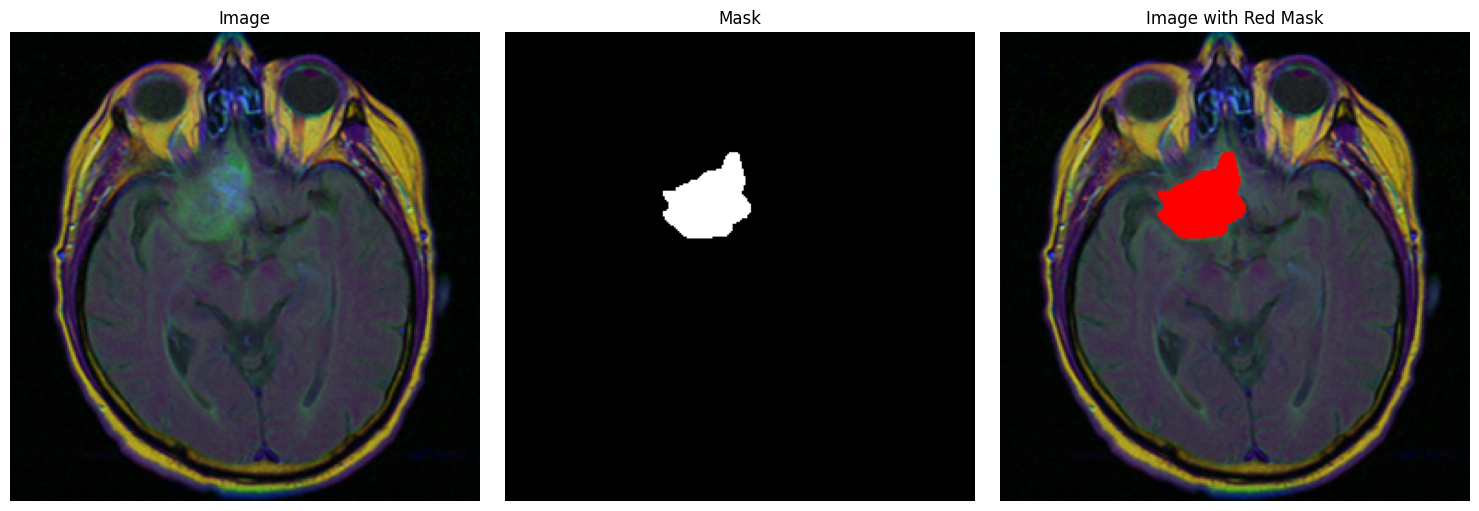

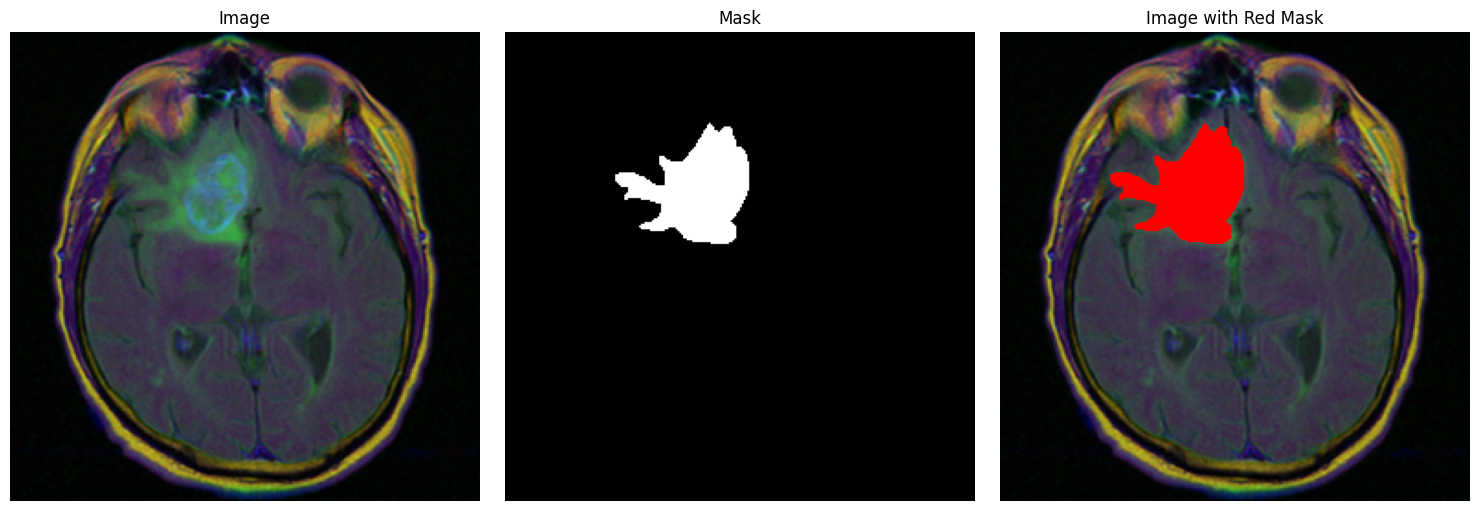

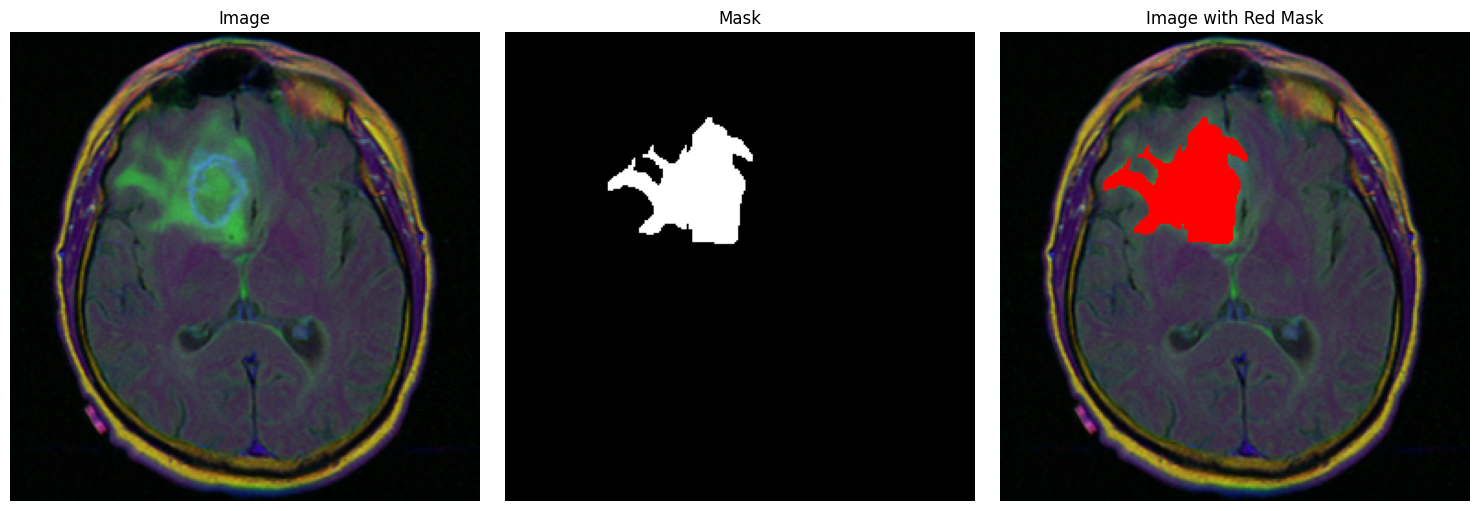

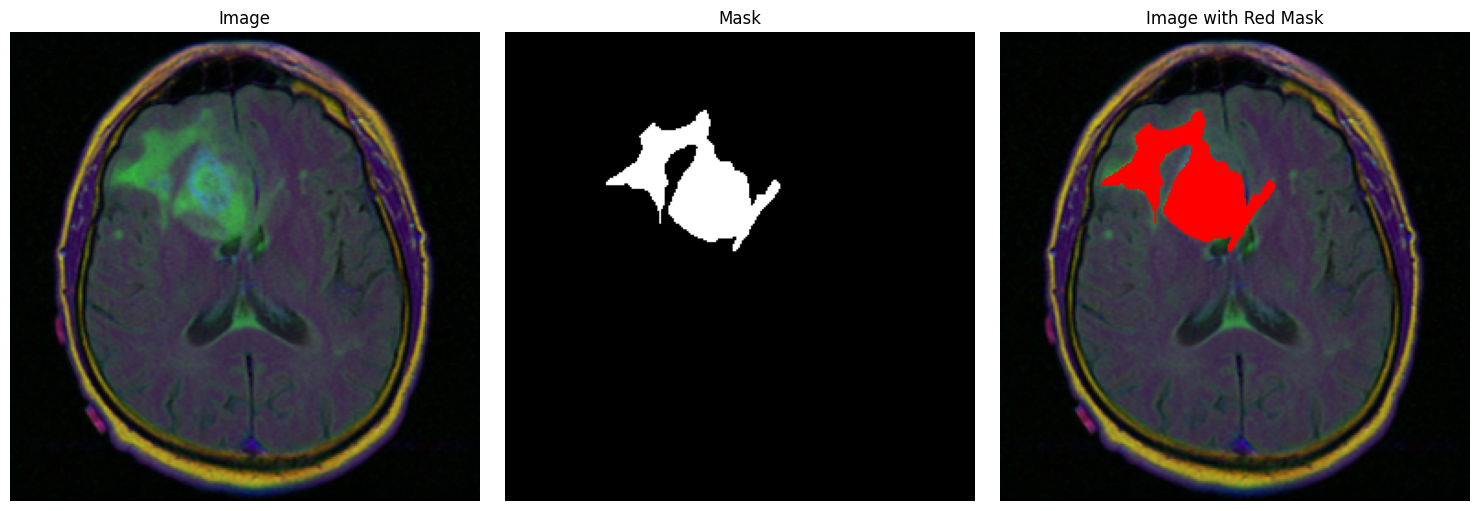

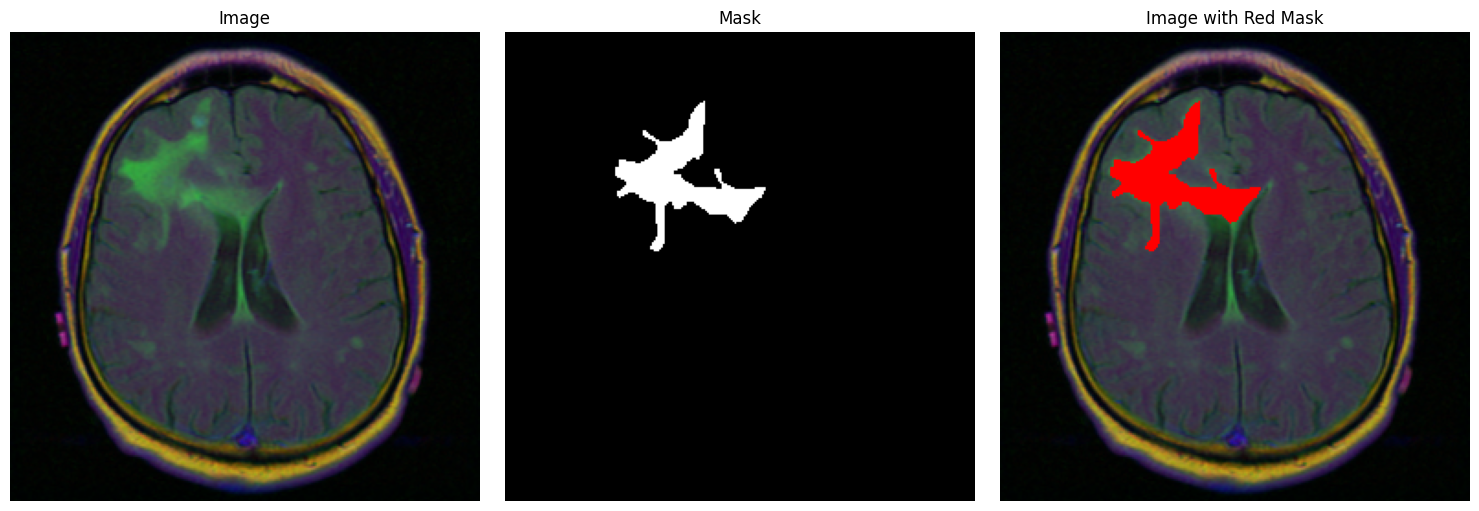

19410

In [46]:
# get the dataframe of 5 img with tumors and 5 img without tumor
tumor_img_5 = data_df[data_df['Tumor'] == 1].head(5)
non_tumor_img_5 = data_df[data_df['Tumor'] == 0].head(5)

# paths for tumor images
tumor_img_paths = tumor_img_5['image_path'].tolist()
tumor_mask_paths = tumor_img_5['mask_path'].tolist()

# paths for non-tumor images
non_tumor_image_paths = non_tumor_img_5['image_path'].tolist()
non_tumor_mask_paths = non_tumor_img_5['mask_path'].tolist()


for i in range(5):
  plot_with_mask(tumor_img_paths[i], tumor_mask_paths[i])

del data_df, tumor_img_5, non_tumor_img_5, tumor_img_paths, tumor_mask_paths,non_tumor_image_paths,non_tumor_mask_paths
gc.collect()

## Preprocessing

In [15]:
img_resized = []
mask_resized = []
mask_without_resize = []
patient_ids = []

for img_path, mask_path in zip(images, masks):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Error reading image: {img_path}")
        continue
    try:
        img = cv2.resize(img, (128, 128))
    except Exception as e:
        print(f"Error resizing image: {img_path} - {e}")
        continue

    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    mask_without_resize.append(mask)
    mask = cv2.resize(mask, (128, 128), interpolation=cv2.INTER_NEAREST)

    img_resized.append(img)
    mask_resized.append(mask)
    patient_ids.append(os.path.basename(os.path.dirname(img_path)))

print("Valid resized images:", len(img_resized))
print("Valid resized masks:", len(mask_resized))
print("Tracked patient IDs:", len(patient_ids))
del images, masks
gc.collect()

Valid resized images: 3929
Valid resized masks: 3929
Tracked patient IDs: 3929


0

In [16]:
print("Images:", len(img_resized))
print("Masks:", len(mask_resized))
print("Patient IDs:", len(patient_ids))

if len(mask_resized) > 0:
    print("First mask shape:", mask_resized[0].shape)
    print("First mask values:", np.unique(mask_resized[0]))
else:
    print("mask_resized is EMPTY!")

Images: 3929
Masks: 3929
Patient IDs: 3929
First mask shape: (128, 128)
First mask values: [0]


In [17]:
# make the mask value between 0 and 1
mask_resized_nor = []
for each_mask in mask_resized:
  each_mask = each_mask.astype(np.float32)  # Convert to float type
  each_mask /= 255
  mask_resized_nor.append(each_mask)

print("values of masks after /255:", np.unique(mask_resized_nor))
print(mask_resized_nor[1].shape)


values of masks after /255: [0. 1.]
(128, 128)


In [18]:
# Normalize the images (MinMaxScaler): MinMaxScaler normalize each channel of the image separately
from sklearn.preprocessing import MinMaxScaler
img_nor = []
for each_img in img_resized:
  img_resh = each_img.reshape(-1, each_img.shape[-1])
  scaler = MinMaxScaler()
  each_img_nor = scaler.fit_transform(img_resh)
  each_img_nor = each_img_nor.reshape(each_img.shape)
  img_nor.append(each_img_nor)
print(img_nor[1].shape)

(128, 128, 3)


In [19]:
from sklearn.model_selection import GroupShuffleSplit

img_arr = np.array(img_nor)
mask_arr = np.array(mask_resized_nor)
patient_arr = np.array(patient_ids)

# 80% patients Train, 20% Val+Test
gss_train = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, temp_idx = next(gss_train.split(img_arr, mask_arr, groups=patient_arr))

X_train, y_train = img_arr[train_idx], mask_arr[train_idx]
X_temp, y_temp = img_arr[temp_idx], mask_arr[temp_idx]
patients_temp = patient_arr[temp_idx]

# Split remaining 20% equally into 10% Val and 10% Test by patient
gss_val_test = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss_val_test.split(X_temp, y_temp, groups=patients_temp))

X_val, y_val = X_temp[val_idx], y_temp[val_idx]
X_test, y_test = X_temp[test_idx], y_temp[test_idx]

del img_nor, img_resized, mask_resized_nor
gc.collect()

0

In [20]:
class CustomDataset(Dataset):
  def __init__(self, images_list, masks_list, transform=None, mode='Train'):
    self.images = images_list
    self.masks = masks_list
    self.transform = transform
    self.transform_main = albumentations.Compose([ToTensorV2()])
    self.mode = mode

    # Create augmented images and masks make the data
    augmented_images = []
    augmented_masks = []
    for img, mask in zip(images_list, masks_list):
      if self.mode =='Train':
        augmented_data = self.transform_main(image=img, mask=mask)
        augmented_images.append(augmented_data['image'])
        augmented_masks.append(augmented_data['mask'])
        for i in range(2):
          augmented_data = self.transform(image=img, mask=mask)
          augmented_images.append(augmented_data['image'])
          augmented_masks.append(augmented_data['mask'])
      else:
        augmented_data = self.transform(image=img, mask=mask)
        augmented_images.append(augmented_data['image'])
        augmented_masks.append(augmented_data['mask'])

    self.images = augmented_images
    self.masks = augmented_masks


  def __len__(self):
    return len(self.images)


  def __getitem__(self, idx):
    image = self.images[idx]
    mask = self.masks[idx]

    return image, mask

In [21]:
transform_train = albumentations.Compose([
    albumentations.HorizontalFlip(p=0.5),  # Apply horizontal flip with 50% probability
    albumentations.VerticalFlip(p=0.5),    # Apply vertical flip with 50% probability
    albumentations.RandomRotate90(p=0.5),  # Apply random 90 degree rotation with 50% probability
    ToTensorV2()                            # Convert image and mask to PyTorch tensor
])

In [22]:
transform_val = albumentations.Compose([
     ToTensorV2()                          # Convert image and mask to PyTorch tensor
])

In [23]:
print("X_train.shap:",X_train.shape)
print("X_test.shap:",X_test.shape)
print("X_val.shap:",X_val.shape)

X_train.shap: (3151, 128, 128, 3)
X_test.shap: (331, 128, 128, 3)
X_val.shap: (447, 128, 128, 3)


In [24]:
train_dataset = CustomDataset(X_train, y_train, transform_train, mode='Train')
val_dataset = CustomDataset(X_val, y_val, transform_val, mode='Val')
test_dataset = CustomDataset(X_test, y_test, transform_val, mode='Test')

In [25]:
print(train_dataset[0][0].shape)  #train_dataset[0] is the first item and train_dataset[0][0] is the imag of first item
print(train_dataset[0][1].shape)  # train_dataset[0][0] is the mask of first item
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

torch.Size([3, 128, 128])
torch.Size([128, 128])
9453
447
331


In [26]:
img_train, mask_train = train_dataset[0]
print(img_train.type)
print(mask_train.type)
print(np.shape(img_train))
print(np.shape(mask_train))

<built-in method type of Tensor object at 0x7978031299a0>
<built-in method type of Tensor object at 0x7977fb727430>
torch.Size([3, 128, 128])
torch.Size([128, 128])


In [27]:
# Create train, validation data_loaders
batch_size = 32                                                                                             #####################################################################
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

torch.Size([32, 3, 128, 128])
torch.Size([3, 128, 128])
torch.Size([32, 128, 128])


<function gc.collect(generation=2)>

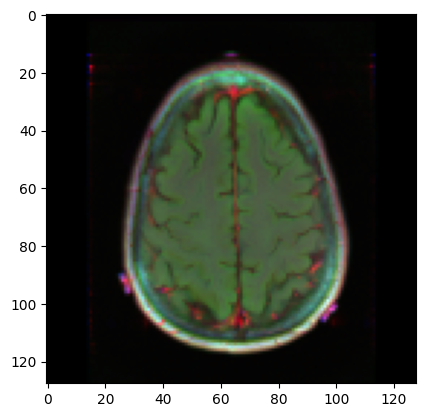

In [28]:
sample = next(iter(train_loader))
print(sample[0].shape)    #sample[0] show the images
print(sample[0][1].shape) #sample[0][1] show one of the images
print(sample[1].shape)    #sample[1] show the masks


plt.imshow(sample[0][1].permute(1,2,0))

del sample
gc.collect

10
10
torch.Size([3, 128, 128])


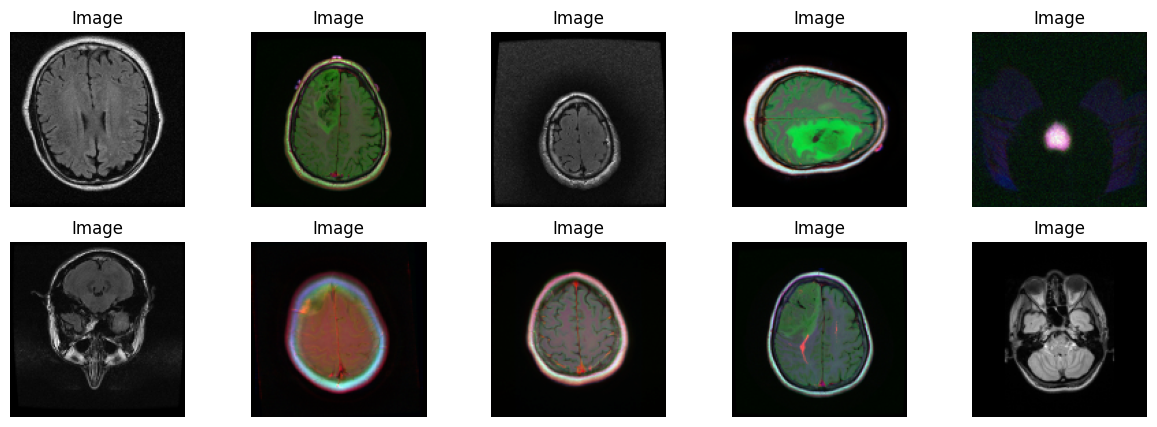

<function gc.collect(generation=2)>

In [29]:
# Show the augmented images and masks
sample_images = []
sample_masks = []
for i in range(10):
  sample = next(iter(train_loader))
  sample_images.append(sample[0][i])
  sample_masks.append(sample[1][i])
print(len(sample_images))
print(len(sample_masks))
x = sample_images[1]
print(x.shape)


fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for i in range(10):
    image = sample[0][i].permute(1, 2, 0)  # Transpose dimensions from (channels, height, width) to (height, width, channels)

    axes[i // 5, i % 5].imshow(image)
    axes[i // 5, i % 5].set_title('Image')
    axes[i // 5, i % 5].axis('off')

plt.show()

del sample_images,sample_masks
gc.collect

torch.Size([128, 128])


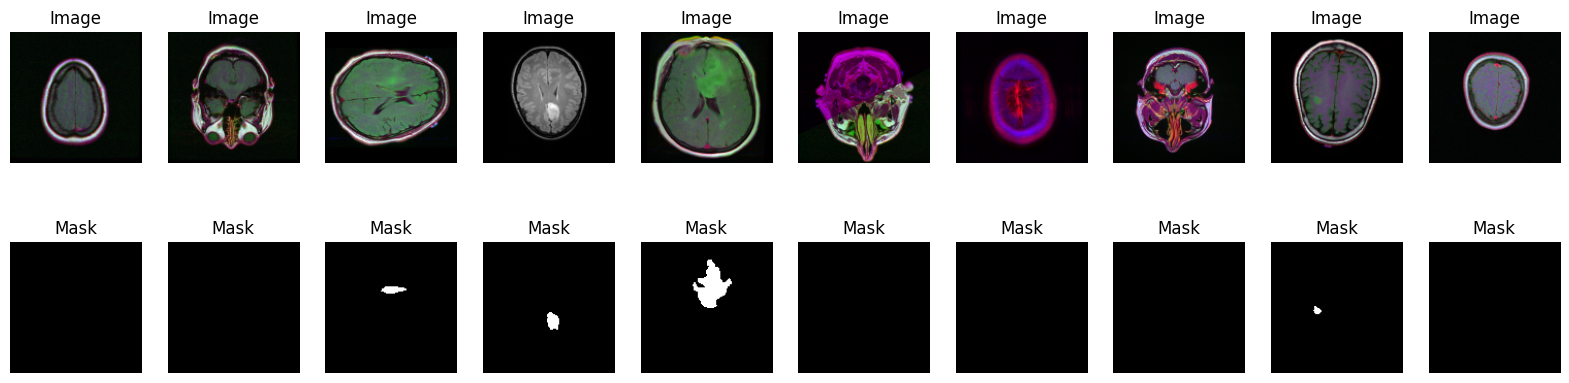

<function gc.collect(generation=2)>

In [30]:
# Plot augmented images and masks
sample_images = []
sample_masks = []
for i in range(10):
    sample = next(iter(train_loader))
    sample_images.append(sample[0][i].permute(1, 2, 0))  # Transpose dimensions from (channels, height, width) to (height, width, channels)
    sample_masks.append(sample[1][i])

print(sample_masks[1].shape)

fig, axes = plt.subplots(2, 10, figsize=(20, 5))

for i in range(10):
    image = sample_images[i].cpu().numpy()
    mask = sample_masks[i].cpu().numpy()

    # Plot the image
    axes[0, i].imshow(image)
    axes[0, i].set_title('Image')
    axes[0, i].axis('off')

    # Plot the mask
    axes[1, i].imshow(mask, cmap='gray')
    axes[1, i].set_title('Mask')
    axes[1, i].axis('off')

plt.show()

del sample_images, sample_masks
gc.collect

## UNET Model



In [31]:
class Double_Conv(nn.Module):
  def __init__(self, input_channel, output_channel):
    super().__init__()
    self.double_conv = nn.Sequential(
        nn.Conv2d(input_channel, output_channel, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(output_channel),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Conv2d(output_channel, output_channel, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(output_channel),
        nn.ReLU(),
        nn.Dropout(0.1),
    )

  def forward(self, x):
      return self.double_conv(x)


class Down(nn.Module):      #Downscale (maxpool) and double conv
  def __init__(self, input_channel, output_channel):
    super().__init__()
    self.maxpool_conv = nn.Sequential(
        nn.MaxPool2d(2),
        Double_Conv(input_channel, output_channel)
    )

  def forward(self, x):
      return self.maxpool_conv(x)


class Up(nn.Module):    #Upscale (maxpool) and double conv

  def __init__(self, input_channel, output_channel, bilinear=False):
    super().__init__()
    if bilinear:
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv = Double_Conv(input_channel, output_channel)  ##??????????????/delete the input_channel//2
    else:
        self.up = nn.ConvTranspose2d(input_channel, input_channel // 2, kernel_size=2, stride=2)
        self.conv = Double_Conv(input_channel, output_channel)

  def forward(self, x1, x2):      #**********************************************************
    x1 = self.up(x1)
    # Adjust padding to handle odd input sizes
    diffY = x2.size()[2] - x1.size()[2]
    diffX = x2.size()[3] - x1.size()[3]
    x1 = nn.functional.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2])
    x = torch.cat([x2, x1], dim=1)
    return self.conv(x)


class Out_Conv(nn.Module):
  def __init__(self, input_chennel, output_channel):
    super(Out_Conv, self).__init__()
    self.conv = nn.Conv2d(input_chennel, output_channel, kernel_size=1)
    self.sigmoid = nn.Sigmoid()

  def forward(self,x):
    x=self.conv(x)
    return self.sigmoid(x)

In [32]:
class UNET_Model(nn.Module):
  def __init__(self, input_ch, num_classes, bilinear=False):
    super(UNET_Model, self).__init__()
    self.input_ch = input_ch
    self.num_classes = num_classes
    self.bilinear = bilinear

    self.first_input = Double_Conv(input_ch,32)  # Why isn't self.input_ch??
    self.down1 = Down(32, 64)
    self.down2 = Down(64, 128)
    self.down3 = Down(128, 256)
    #self.down4 = Down(256, 512)

    if bilinear == True:
      n = 2
    else:
      n = 1
    self.down4 = Down(256, 512//n)
    self.up1 = Up(512, 256)
    self.up2 = Up(256, 128)
    self.up3 = Up(128, 64)
    self.up4 = Up(64, 32)
    self.last = Out_Conv(32, num_classes)


  def forward(self, x):
    x1 = self.first_input(x)
    x2 = self.down1(x1)
    x3 = self.down2(x2)
    x4 = self.down3(x3)
    x5 = self.down4(x4)
    x = self.up1(x5, x4)
    x = self.up2(x, x3)
    x = self.up3(x, x2)
    x = self.up4(x, x1)
    x = self.last(x)
    return x


In [33]:
sample_val = next(iter(val_loader))  # show the images
print(sample_val[0].shape)
print(sample_val[1].shape)  # show the masks

del sample_val
gc.collect

torch.Size([32, 3, 128, 128])
torch.Size([32, 128, 128])


<function gc.collect(generation=2)>

In [34]:
model1 = UNET_Model(3,1)
sample_2, label_2 = next(iter(val_loader))
sample_2

print(type(sample_2))
print(sample_2.shape)
print(type(label_2))
print("___________________________")
out_model = model1(sample_2.float())
print(out_model.shape)
print(type(out_model))

del model1,sample_2,label_2,out_model
gc.collect

<class 'torch.Tensor'>
torch.Size([32, 3, 128, 128])
<class 'torch.Tensor'>
___________________________
torch.Size([32, 1, 128, 128])
<class 'torch.Tensor'>


<function gc.collect(generation=2)>

##Train the model

In [47]:
torch.cuda.is_available()

True

In [48]:
#https://github.com/Bjarten/early-stopping-pytorch/blob/master/pytorchtools.py

class EarlyStopping:        #Early stops the training if validation loss doesn't improve after a given patience

    def __init__(self, patience=7, verbose=False, delta=0, path='checkpoint.pt', trace_func=print):
        """
        Args:
            patience (int): How long to wait after last time validation loss improved.
                            Default: 7
            verbose (bool): If True, prints a message for each validation loss improvement.
                            Default: False
            delta (float): Minimum change in the monitored quantity to qualify as an improvement.
                            Default: 0
            path (str): Path for the checkpoint to be saved to.
                            Default: 'checkpoint.pt'
            trace_func (function): trace print function.
                            Default: print
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf
        self.delta = delta
        self.path = path
        self.trace_func = trace_func
    def __call__(self, val_loss, model):

        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            self.trace_func(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        '''Saves model when validation loss decrease.'''
        if self.verbose:
            self.trace_func(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}).  Saving model ...')
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

In [49]:
def dice_coef(mask_true, mask_pred):
  mask_pred = (mask_pred > 0.5).float()
  dice_list = []
  for each_mask_true, each_mask_pred in zip(mask_true, mask_pred):
    intersection = torch.sum(each_mask_true * each_mask_pred, dim=[1,2])
    union = torch.sum(each_mask_true, dim=[1,2]) + torch.sum(each_mask_pred, dim=[1,2])
    dice = (2. * intersection + 1e-5) / (union + 1e-5)
    dice_list.append(dice.cpu().item())
  dice_mean_batch = np.mean(dice_list)
  return  dice_mean_batch

In [50]:
def compute_IoU(mask_true, mask_pred, threshold=0.5):
    mask_pred = (mask_pred > threshold).float()  # Apply threshold

    #mask_true = mask_true.to(mask_pred.device)

    # Flatten, (batch_size, -1)
    mask_true_flat = mask_true.view(mask_true.size(0), -1)
    mask_pred_flat = mask_pred.view(mask_pred.size(0), -1)

    intersection = torch.sum(mask_true_flat * mask_pred_flat, dim=1)
    union = torch.sum(mask_true_flat, dim=1) + torch.sum(mask_pred_flat, dim=1) - intersection
    iou = (intersection + 1e-10) / (union + 1e-10)

    return iou.mean().cpu().item()

In [51]:
def accuracy(mask_pred, mask_true):           #???????????????????????????
    with torch.no_grad():
        batch_size = mask_true.size(0)
        # Flatten
        mask_pred = mask_pred.view(batch_size,-1)
        mask_true = mask_true.view(batch_size,-1)

        mask_pred = (mask_pred > 0.5).float()

        correct = (mask_pred == mask_true).float().sum(dim=1)

        accuracy_values = correct / mask_true.size(1)   # Divide by number of elements in each mask after flatting

        return accuracy_values.mean().item()

In [53]:
# Training with Early Stopping
epochs = 50
learning_rate = 0.001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_unet = UNET_Model(3, 1).to(device)
loss_fn = nn.BCELoss()
optimizer = optim.Adam(model_unet.parameters(), lr=learning_rate)

acc_train, loss_train = [], []
acc_val, loss_val = [], []
dice_train, dice_val = [], []
IoU_train, IoU_val = [], []

early_stopping = EarlyStopping(patience=10, verbose=True, path="checkpoint.pt")

for epoch in range(1, epochs + 1):
    sum_train_acc_epoch = 0.0
    sum_train_loss_epoch = 0.0
    train_iou = 0.0
    train_dice = 0.0

    model_unet.train()
    train_log_step = max(1, round(len(train_loader) / 6))

    for batch_idx, (images, masks) in enumerate(train_loader, 1):
        images = images.to(device)
        masks = masks.unsqueeze(1).to(device)

        optimizer.zero_grad()
        masks_pred = model_unet(images.float())
        loss = loss_fn(masks_pred.float(), masks.float())

        loss.backward()
        optimizer.step()

        sum_train_acc_epoch += accuracy(masks_pred, masks)
        sum_train_loss_epoch += loss.detach().item()
        train_iou += compute_IoU(masks, masks_pred)
        train_dice += dice_coef(masks, masks_pred)

        if batch_idx % train_log_step == 0:
            print(
                f"Epoch {epoch} [Train {batch_idx}/{len(train_loader)}] -> "
                f"Acc: {(sum_train_acc_epoch/batch_idx)*100:.2f}% | "
                f"Loss: {sum_train_loss_epoch/batch_idx:.4f} | "
                f"IoU: {train_iou/batch_idx:.4f} | "
                f"Dice: {train_dice/batch_idx:.4f}"
            )

    acc_train.append(sum_train_acc_epoch / batch_idx)
    loss_train.append(sum_train_loss_epoch / batch_idx)
    dice_train.append(train_dice / batch_idx)
    IoU_train.append(train_iou / batch_idx)

    # Validation phase
    model_unet.eval()
    sum_val_acc_epoch = 0.0
    sum_val_loss_epoch = 0.0
    val_iou = 0.0
    val_dice = 0.0
    val_log_step = max(1, round(len(val_loader) / 6))

    with torch.no_grad():
        for batch_idx, (images, masks) in enumerate(val_loader, 1):
            images = images.to(device)
            masks = masks.unsqueeze(1).to(device)

            masks_pred = model_unet(images.float())
            loss = loss_fn(masks_pred.float(), masks.float())

            sum_val_acc_epoch += accuracy(masks_pred, masks)
            sum_val_loss_epoch += loss.detach().item()
            val_iou += compute_IoU(masks, masks_pred)
            val_dice += dice_coef(masks, masks_pred)

            if batch_idx % val_log_step == 0:
                print(
                    f"Epoch {epoch} [Val {batch_idx}/{len(val_loader)}] -> "
                    f"Acc: {(sum_val_acc_epoch/batch_idx)*100:.2f}% | "
                    f"Loss: {sum_val_loss_epoch/batch_idx:.4f} | "
                    f"IoU: {val_iou/batch_idx:.4f} | "
                    f"Dice: {val_dice/batch_idx:.4f}"
                )

    val_loss_epoch = sum_val_loss_epoch / batch_idx
    acc_val.append(sum_val_acc_epoch / batch_idx)
    loss_val.append(val_loss_epoch)
    dice_val.append(val_dice / batch_idx)
    IoU_val.append(val_iou / batch_idx)

    early_stopping(val_loss_epoch, model_unet)
    if early_stopping.early_stop:
        print("Early stopping")
        break

# Load the best saved checkpoint
model_unet.load_state_dict(torch.load("checkpoint.pt", map_location=device))

Epoch 1 [Train 49/296] -> Acc: 98.61% | Loss: 0.2753 | IoU: 0.4914 | Dice: 0.5103
Epoch 1 [Train 98/296] -> Acc: 98.93% | Loss: 0.2069 | IoU: 0.5865 | Dice: 0.6083
Epoch 1 [Train 147/296] -> Acc: 98.99% | Loss: 0.1685 | IoU: 0.6144 | Dice: 0.6367
Epoch 1 [Train 196/296] -> Acc: 99.08% | Loss: 0.1424 | IoU: 0.6302 | Dice: 0.6533
Epoch 1 [Train 245/296] -> Acc: 99.12% | Loss: 0.1239 | IoU: 0.6430 | Dice: 0.6672
Epoch 1 [Train 294/296] -> Acc: 99.16% | Loss: 0.1101 | IoU: 0.6519 | Dice: 0.6773
Epoch 1 [Val 2/14] -> Acc: 99.58% | Loss: 0.0299 | IoU: 0.8168 | Dice: 0.8498
Epoch 1 [Val 4/14] -> Acc: 98.91% | Loss: 0.0530 | IoU: 0.7523 | Dice: 0.7690
Epoch 1 [Val 6/14] -> Acc: 98.93% | Loss: 0.0504 | IoU: 0.7176 | Dice: 0.7372
Epoch 1 [Val 8/14] -> Acc: 98.43% | Loss: 0.0618 | IoU: 0.5878 | Dice: 0.6070
Epoch 1 [Val 10/14] -> Acc: 98.66% | Loss: 0.0551 | IoU: 0.6111 | Dice: 0.6307
Epoch 1 [Val 12/14] -> Acc: 98.81% | Loss: 0.0512 | IoU: 0.6324 | Dice: 0.6564
Epoch 1 [Val 14/14] -> Acc: 98.62%

<All keys matched successfully>

In [54]:
# print the accuracy and loss in train and vaidation
print("Accuracy of training(last epoch): ", acc_train[-1]*100)
print("Loss of training(last epoch): ", loss_train[-1])
print("Accuracy of valiation(last epoch): ", acc_val[-1]*100)
print("Loss of valiation(last epoch): ", loss_val[-1])
print("__________________________________________")
print("Dice in training (last epoch): ", dice_train[-1])
print("Dice in validation (last epoch): ", dice_val[-1])

print("IoU in training (last epoch): ", IoU_train[-1])
print("IoU in validation (last epoch): ", IoU_val[-1])

Accuracy of training(last epoch):  99.80104396472106
Loss of training(last epoch):  0.005050378665170708
Accuracy of valiation(last epoch):  99.52989901815143
Loss of valiation(last epoch):  0.02566047540598707
__________________________________________
Dice in training (last epoch):  0.918372625564681
Dice in validation (last epoch):  0.8741977947251892
IoU in training (last epoch):  0.8893806805481782
IoU in validation (last epoch):  0.84902623295784


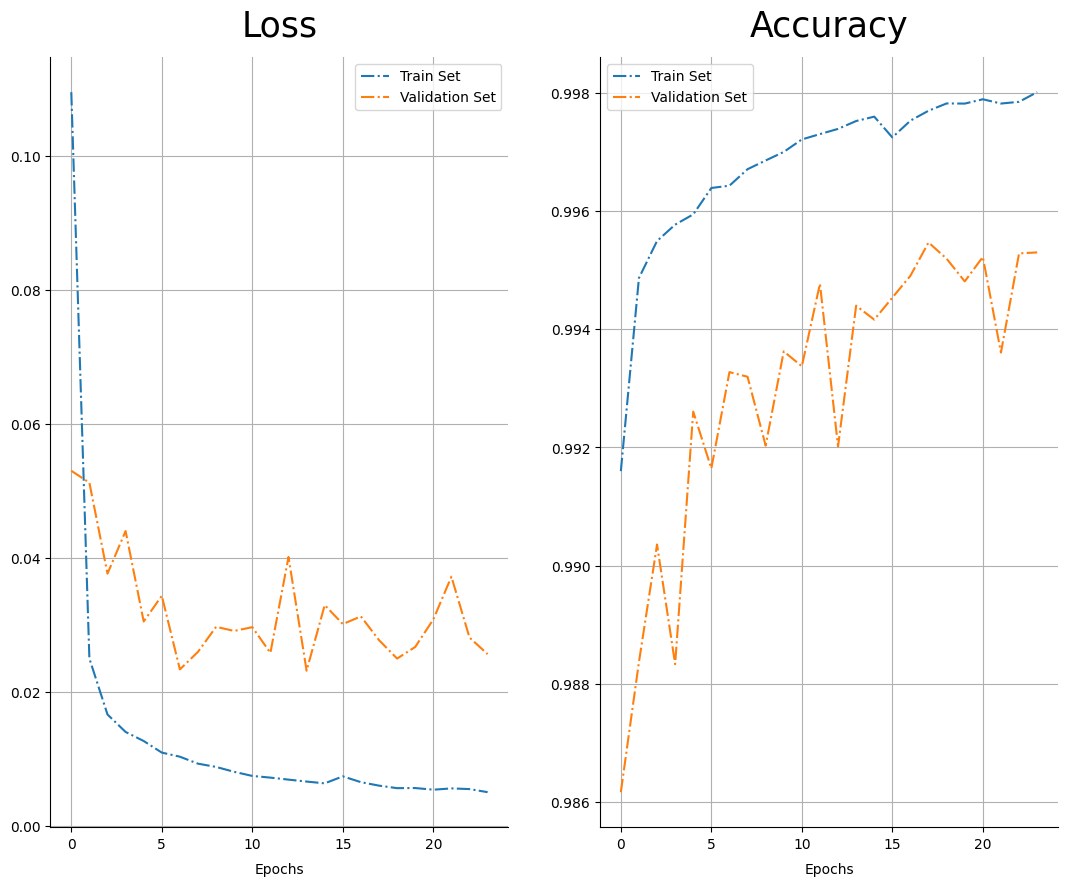

In [55]:
import seaborn as sns
def accloss_plots(train_loss1, test_loss1, train_acc1, test_acc1):
    plt.figure(figsize=(13, 10))

    # Plot training loss for all sets
    plt.subplot(121)
    plt.plot(train_loss1, '-.', label='Train Set')
    plt.plot(test_loss1, '-.', label='Validation Set')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Loss', fontsize=25, pad=15)
    plt.grid()
    plt.legend()
    sns.despine()

    # Plot training accuracy for all sets
    plt.subplot(122)
    plt.plot(train_acc1, '-.', label='Train Set')
    plt.plot(test_acc1, '-.', label='Validation Set')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Accuracy', fontsize=25, pad=15)
    plt.grid()
    plt.legend()
    sns.despine()

    plt.show()

# Plot the results
accloss_plots(loss_train, loss_val, acc_train, acc_val)

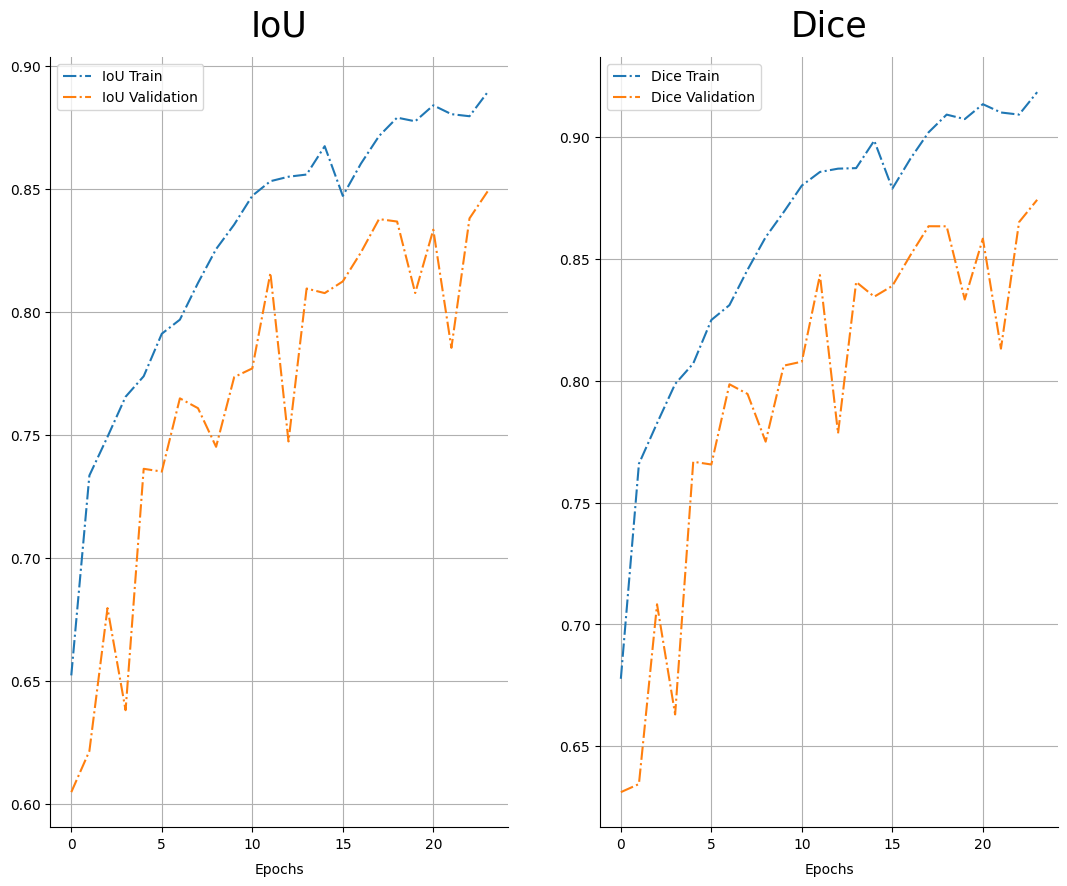

In [56]:
def IoU_Dice_plots(train_iou, val_iou, train_dice, val_dice):
    plt.figure(figsize=(13, 10))
    # Plot IoU for Train vs Validation
    plt.subplot(121)
    plt.plot(train_iou, '-.', label='IoU Train')
    plt.plot(val_iou, '-.', label='IoU Validation')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('IoU', fontsize=25, pad=15)
    plt.grid()
    plt.legend()
    sns.despine()
    # Plot Dice for Train vs Validation
    plt.subplot(122)
    plt.plot(train_dice, '-.', label='Dice Train')
    plt.plot(val_dice, '-.', label='Dice Validation')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Dice', fontsize=25, pad=15)
    plt.grid()
    plt.legend()
    sns.despine()
    plt.show()

IoU_Dice_plots(IoU_train, IoU_val, dice_train, dice_val)

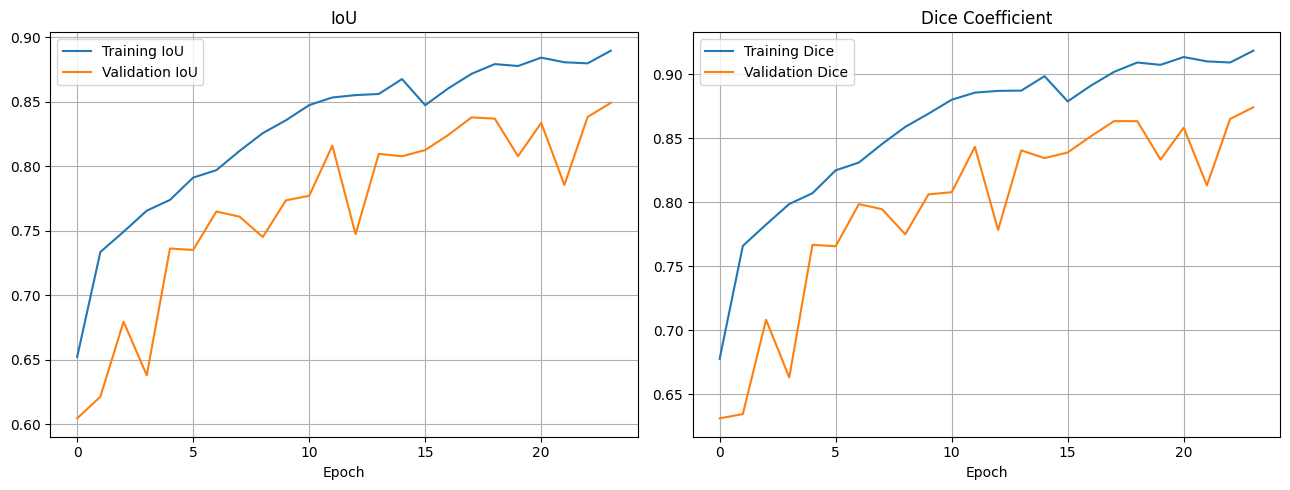

In [57]:
def IoU_Dice_plots(train_iou, val_iou, train_dice, val_dice):

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # IoU
    axes[0].plot(train_iou, label="Training IoU")
    axes[0].plot(val_iou, label="Validation IoU")
    axes[0].set_title("IoU")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[0].grid()

    # Dice
    axes[1].plot(train_dice, label="Training Dice")
    axes[1].plot(val_dice, label="Validation Dice")
    axes[1].set_title("Dice Coefficient")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    axes[1].grid()

    plt.tight_layout()
    plt.show()

# Plot the results
IoU_Dice_plots(IoU_train, IoU_val, dice_train, dice_val)

In [58]:
def test_model(test_loader, model):
    total_loss = 0
    total_accuracy = 0
    total_samples = 0
    total_iou = 0
    total_dice = 0

    model.eval()  # Set model to evaluation mode

    with torch.no_grad():
        for images, masks in test_loader:
            images = images.to(device)
            masks = masks.unsqueeze(1).to(device)  # Ensure masks have shape (batch_size, 1, height, width)

            masks_pred = model(images.float())
            #print(images.shape)
            loss = loss_fn(masks_pred, masks.float())

            total_loss += loss.item() * masks.size(0)
            total_accuracy += accuracy(masks_pred, masks) * masks.size(0)
            total_samples += masks.size(0)

            total_iou += compute_IoU(masks, masks_pred)* masks.size(0)
            total_dice += dice_coef(masks, masks_pred)* masks.size(0)


    average_loss = total_loss / total_samples
    average_accuracy = total_accuracy / total_samples
    average_iou = total_iou / total_samples
    average_dice = total_dice / total_samples

    return average_accuracy, average_loss, average_iou, average_dice

In [59]:

# Test the model
test_accuracy, test_loss, test_iou, test_dice = test_model(test_loader, model_unet)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test IoU: {test_iou:.2f}")
print(f"Test Dice: {test_dice:.4f}")

Test Accuracy: 99.47%
Test Loss: 0.0170
Test IoU: 0.79
Test Dice: 0.8278


In [60]:
#check the accuracy function
# Define the true masks
mask_true = torch.tensor([[[1, 0], [1, 1]], [[0, 1], [1, 1]]])
print("mask_true", mask_true)
# Define the predicted masks
mask_pred = torch.tensor([[[1, 0], [0, 1]], [[0, 1], [1, 1]]])
print("mask_pred", mask_pred)

# Flatten the masks
mask_true_flat = mask_true.view(mask_true.size(0), -1)
mask_pred_flat = mask_pred.view(mask_pred.size(0), -1)
print("mask_true_flat",mask_true_flat)
print("mask_pred_flat",mask_pred_flat)

# Calculate accuracy
correct = (mask_true_flat == mask_pred_flat).float().sum(dim=1)
print("correct",correct)
total_pixels = mask_true_flat.size(1)
print("total_pixels",total_pixels)
accuracy = correct / total_pixels
acc_final = accuracy.mean().item()
print("Correct:", correct)
print("Total Pixels:", total_pixels)
print("Accuracy:", accuracy)
print("Accuracy Final:", acc_final)

mask_true tensor([[[1, 0],
         [1, 1]],

        [[0, 1],
         [1, 1]]])
mask_pred tensor([[[1, 0],
         [0, 1]],

        [[0, 1],
         [1, 1]]])
mask_true_flat tensor([[1, 0, 1, 1],
        [0, 1, 1, 1]])
mask_pred_flat tensor([[1, 0, 0, 1],
        [0, 1, 1, 1]])
correct tensor([3., 4.])
total_pixels 4
Correct: tensor([3., 4.])
Total Pixels: 4
Accuracy: tensor([0.7500, 1.0000])
Accuracy Final: 0.875


## Plot the 5 images, masks, predicted masks from testloader

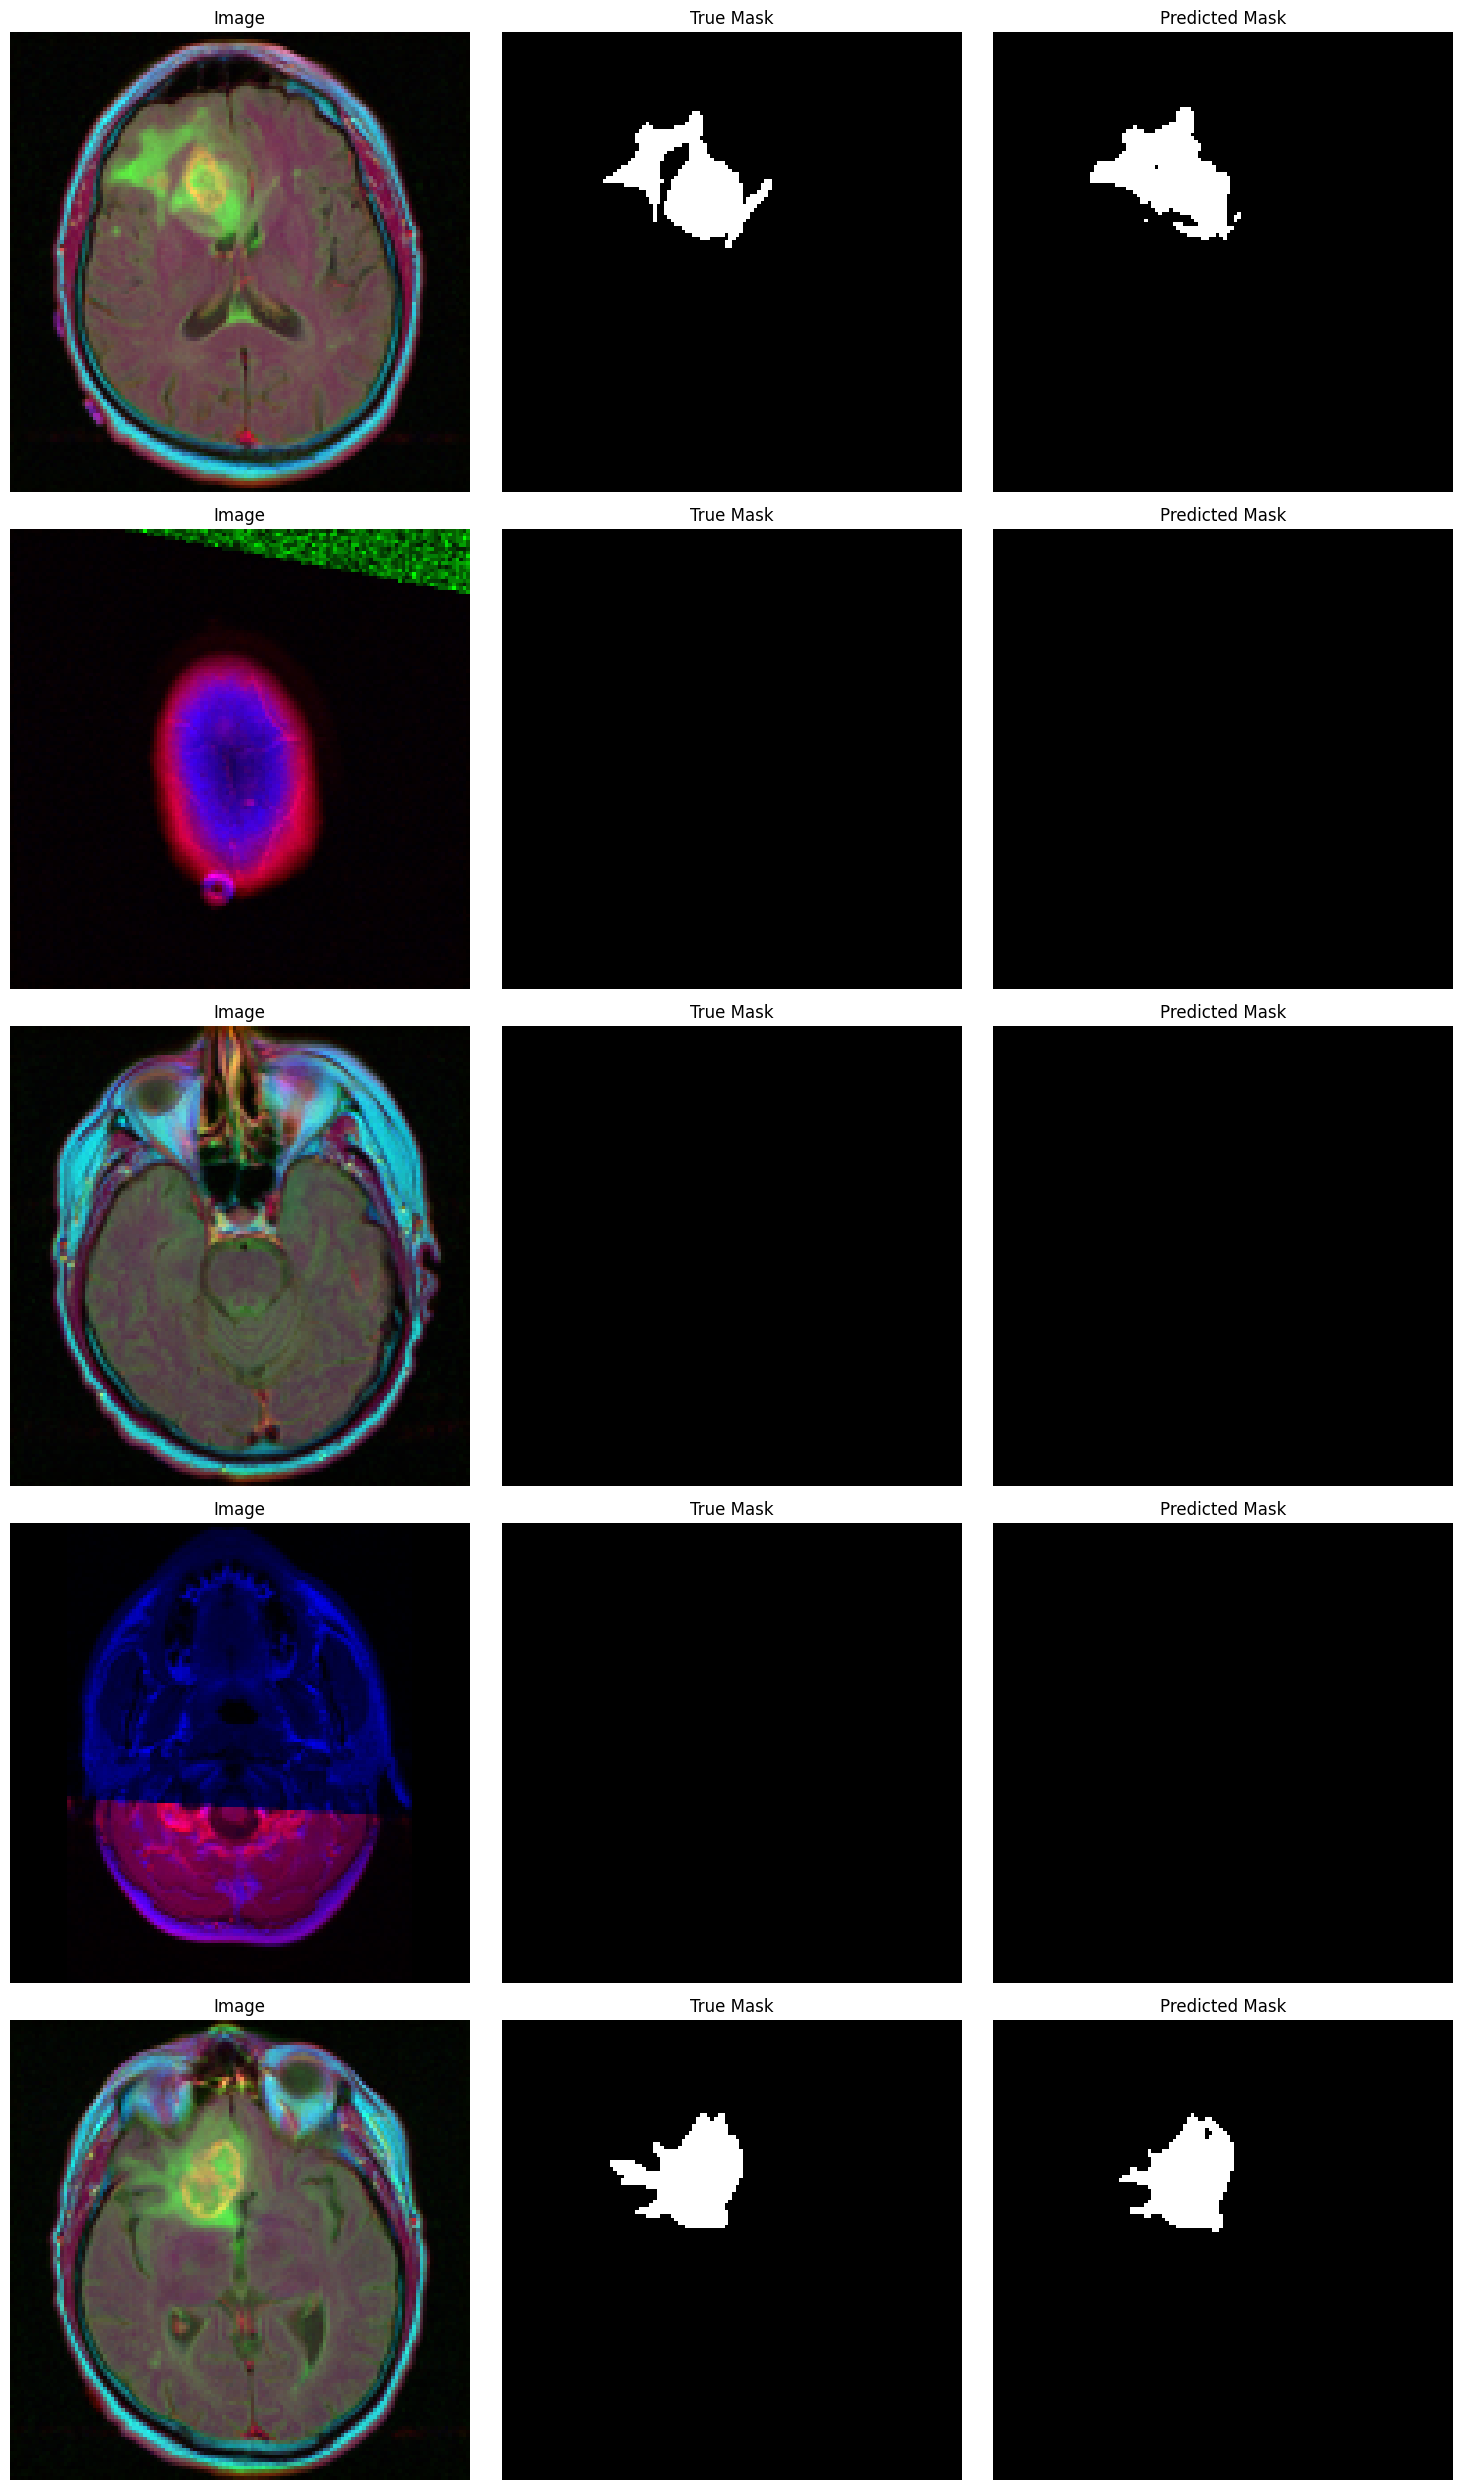

In [61]:
img_list = []
mask_list = []

for img, msk in test_loader:
    img_list.extend(img.cpu())
    mask_list.extend(msk.cpu())
    break  # Exit after the first batch

images = torch.stack(img_list).to(device)
masks = torch.stack(mask_list).unsqueeze(1).to(device)

with torch.no_grad():
    masks_pred = model_unet(images.float())
    masks_pred = (masks_pred > 0.5).float().cpu()  # Apply threshold and move to CPU

random_indices = np.random.choice(len(img_list), 5, replace=False)

# Plot the 5 images, masks_true, masks_pred
num = 5
fig, axes = plt.subplots(num, 3, figsize=(15, num * 5))

for i, idx in enumerate(random_indices):
    img = img_list[idx].numpy().transpose(1, 2, 0)  # Convert to HWC format for plotting
    true_mask = mask_list[idx].numpy()  # Ensure true_mask is in HxW format
    pred_mask = masks_pred[idx][0].numpy().astype(np.uint8)  # Ensure pred_mask is in HxW format

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Image")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(true_mask, cmap='gray')
    axes[i, 1].set_title("True Mask")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_mask, cmap='gray')
    axes[i, 2].set_title("Predicted Mask")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()


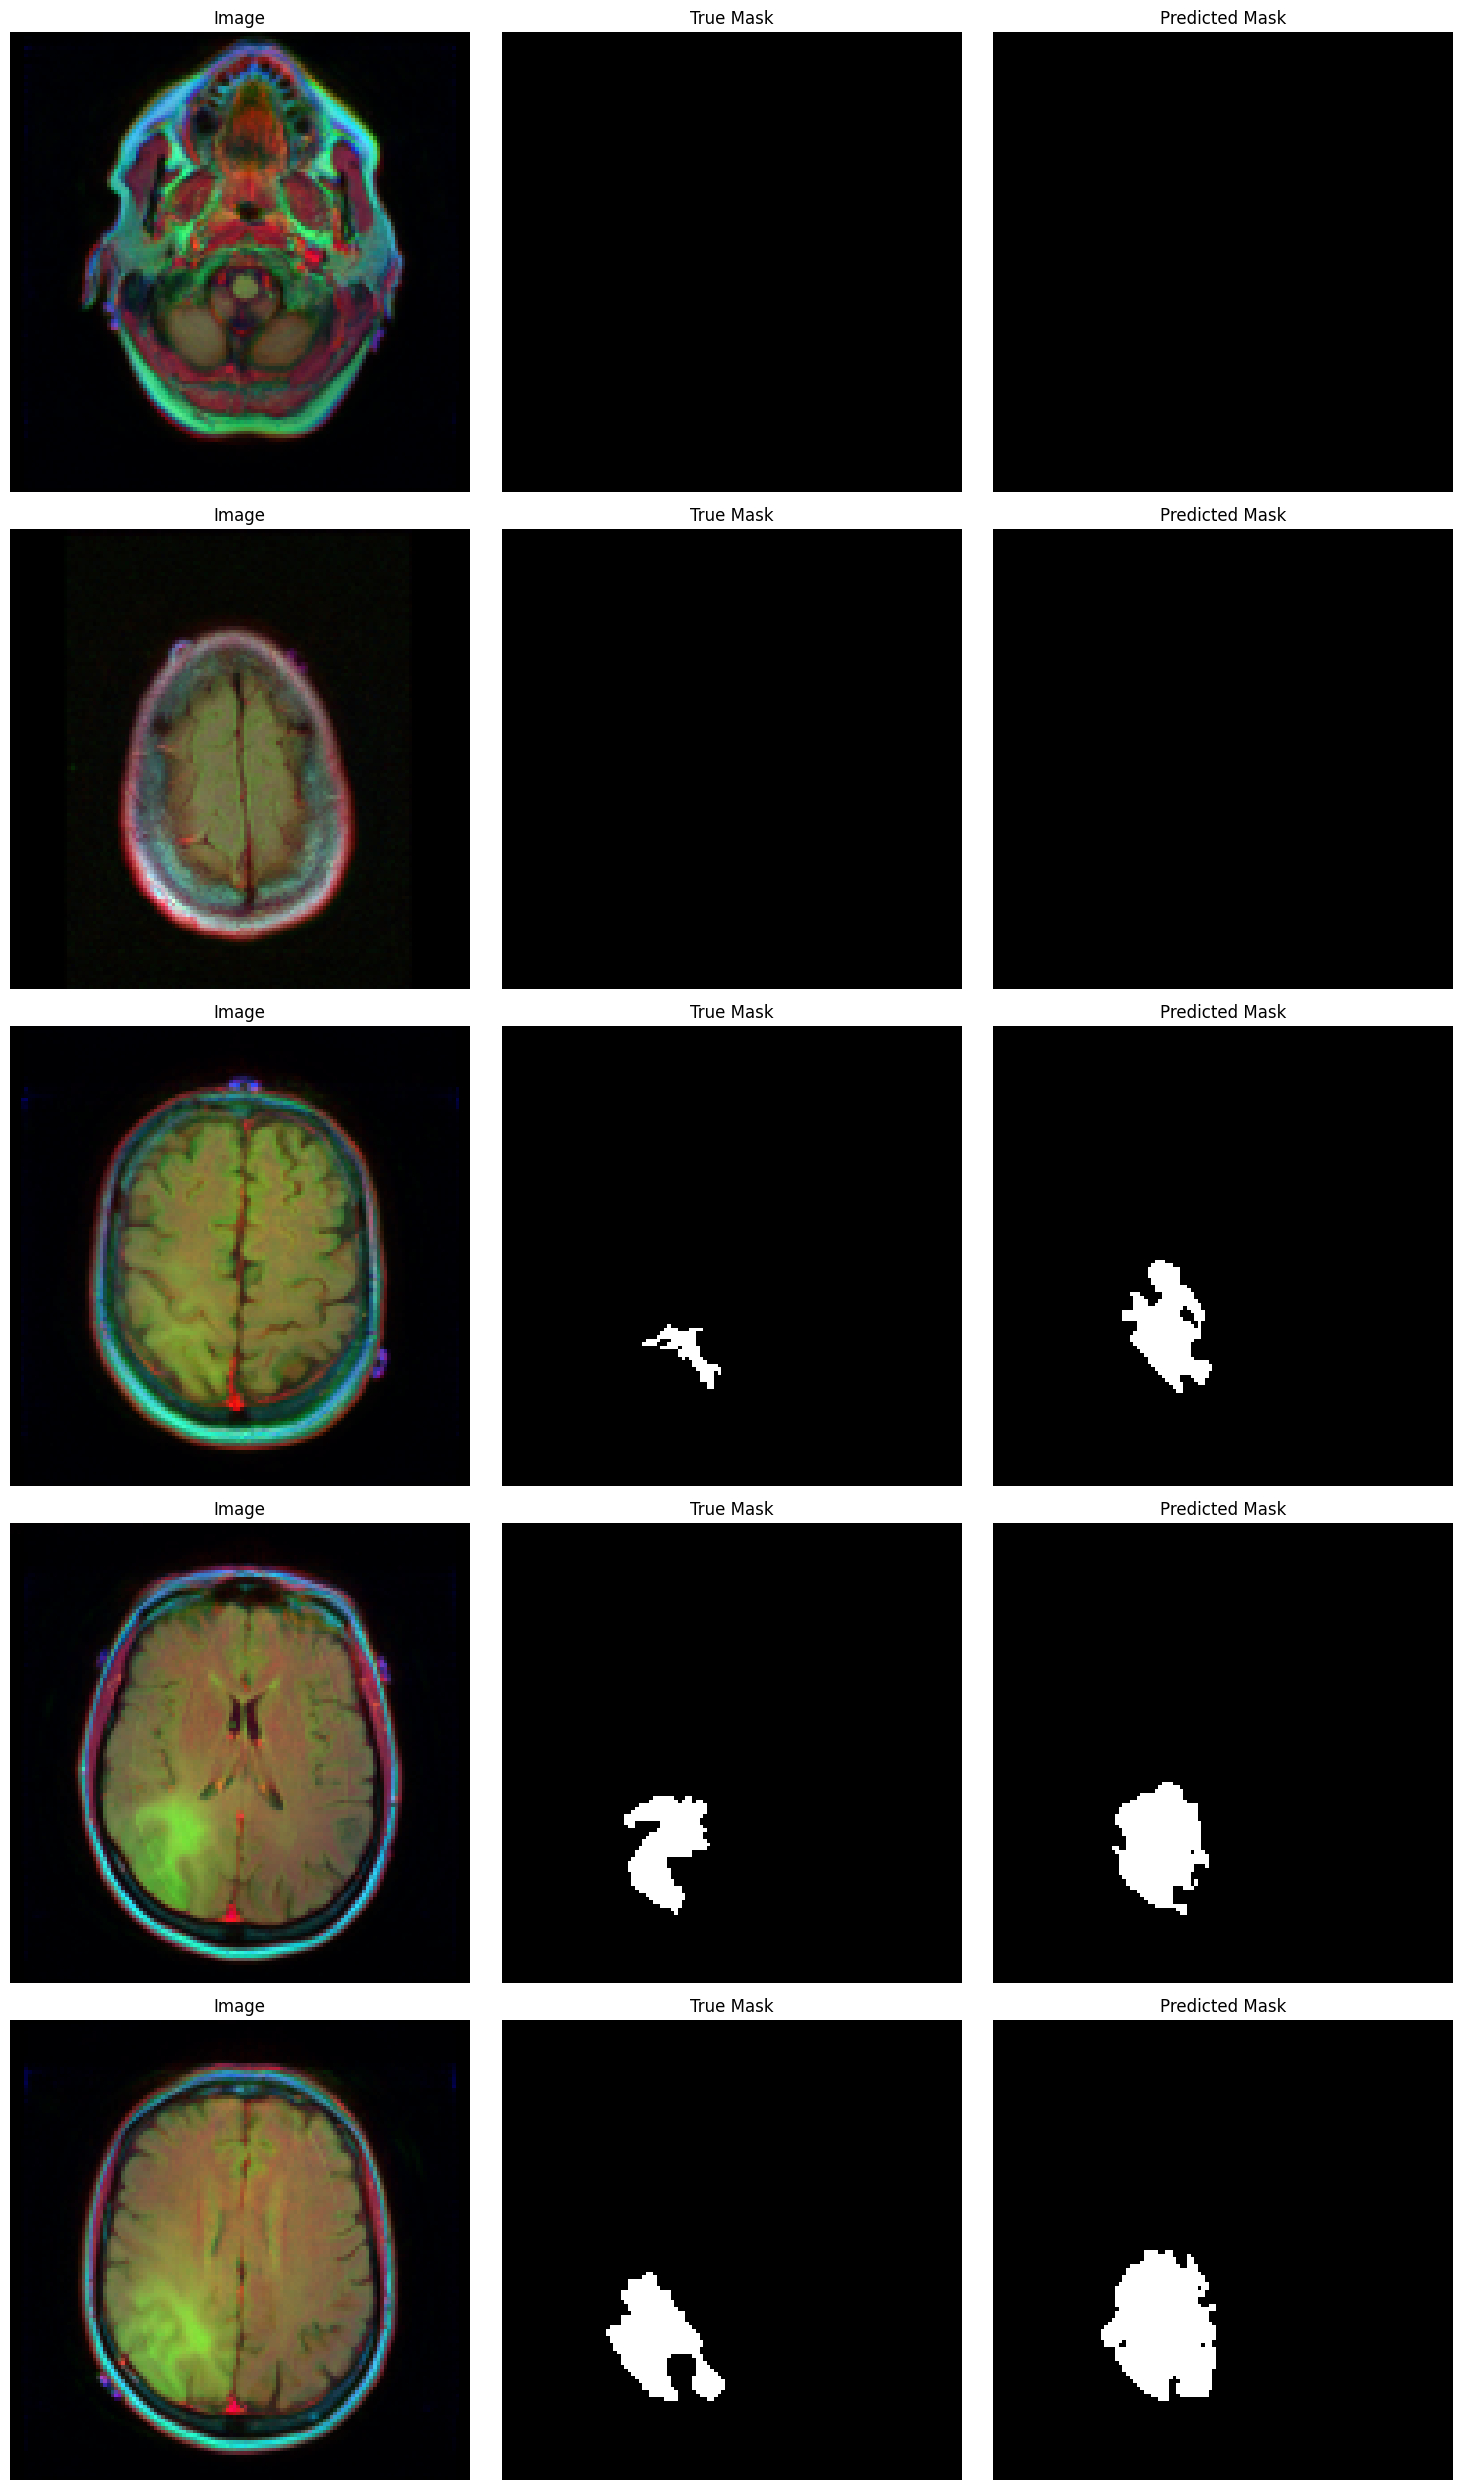

In [62]:
data_iter = iter(test_loader)

first_batch_img, first_batch_msk = next(data_iter)
second_batch_img, second_batch_msk = next(data_iter)

images = second_batch_img.to(device)
masks = second_batch_msk.unsqueeze(1).to(device)

with torch.no_grad():
    masks_pred = model_unet(images.float())
    masks_pred = (masks_pred > 0.5).float()

random_indices = np.random.choice(images.size(0), 5, replace=False)

#Plot the images, true masks, and predicted masks
num = 5
fig, axes = plt.subplots(num, 3, figsize=(15, num * 5))

for i, idx in enumerate(random_indices):
    img = images[idx].cpu().numpy().transpose(1, 2, 0)  # Convert to HWC format for plotting
    true_mask = masks[idx][0].cpu().numpy()  # Convert to HxW format
    pred_mask = masks_pred[idx][0].cpu().numpy().astype(np.uint8)  # Convert to HxW format

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Image")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(true_mask, cmap='gray')
    axes[i, 1].set_title("True Mask")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_mask, cmap='gray')
    axes[i, 2].set_title("Predicted Mask")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()


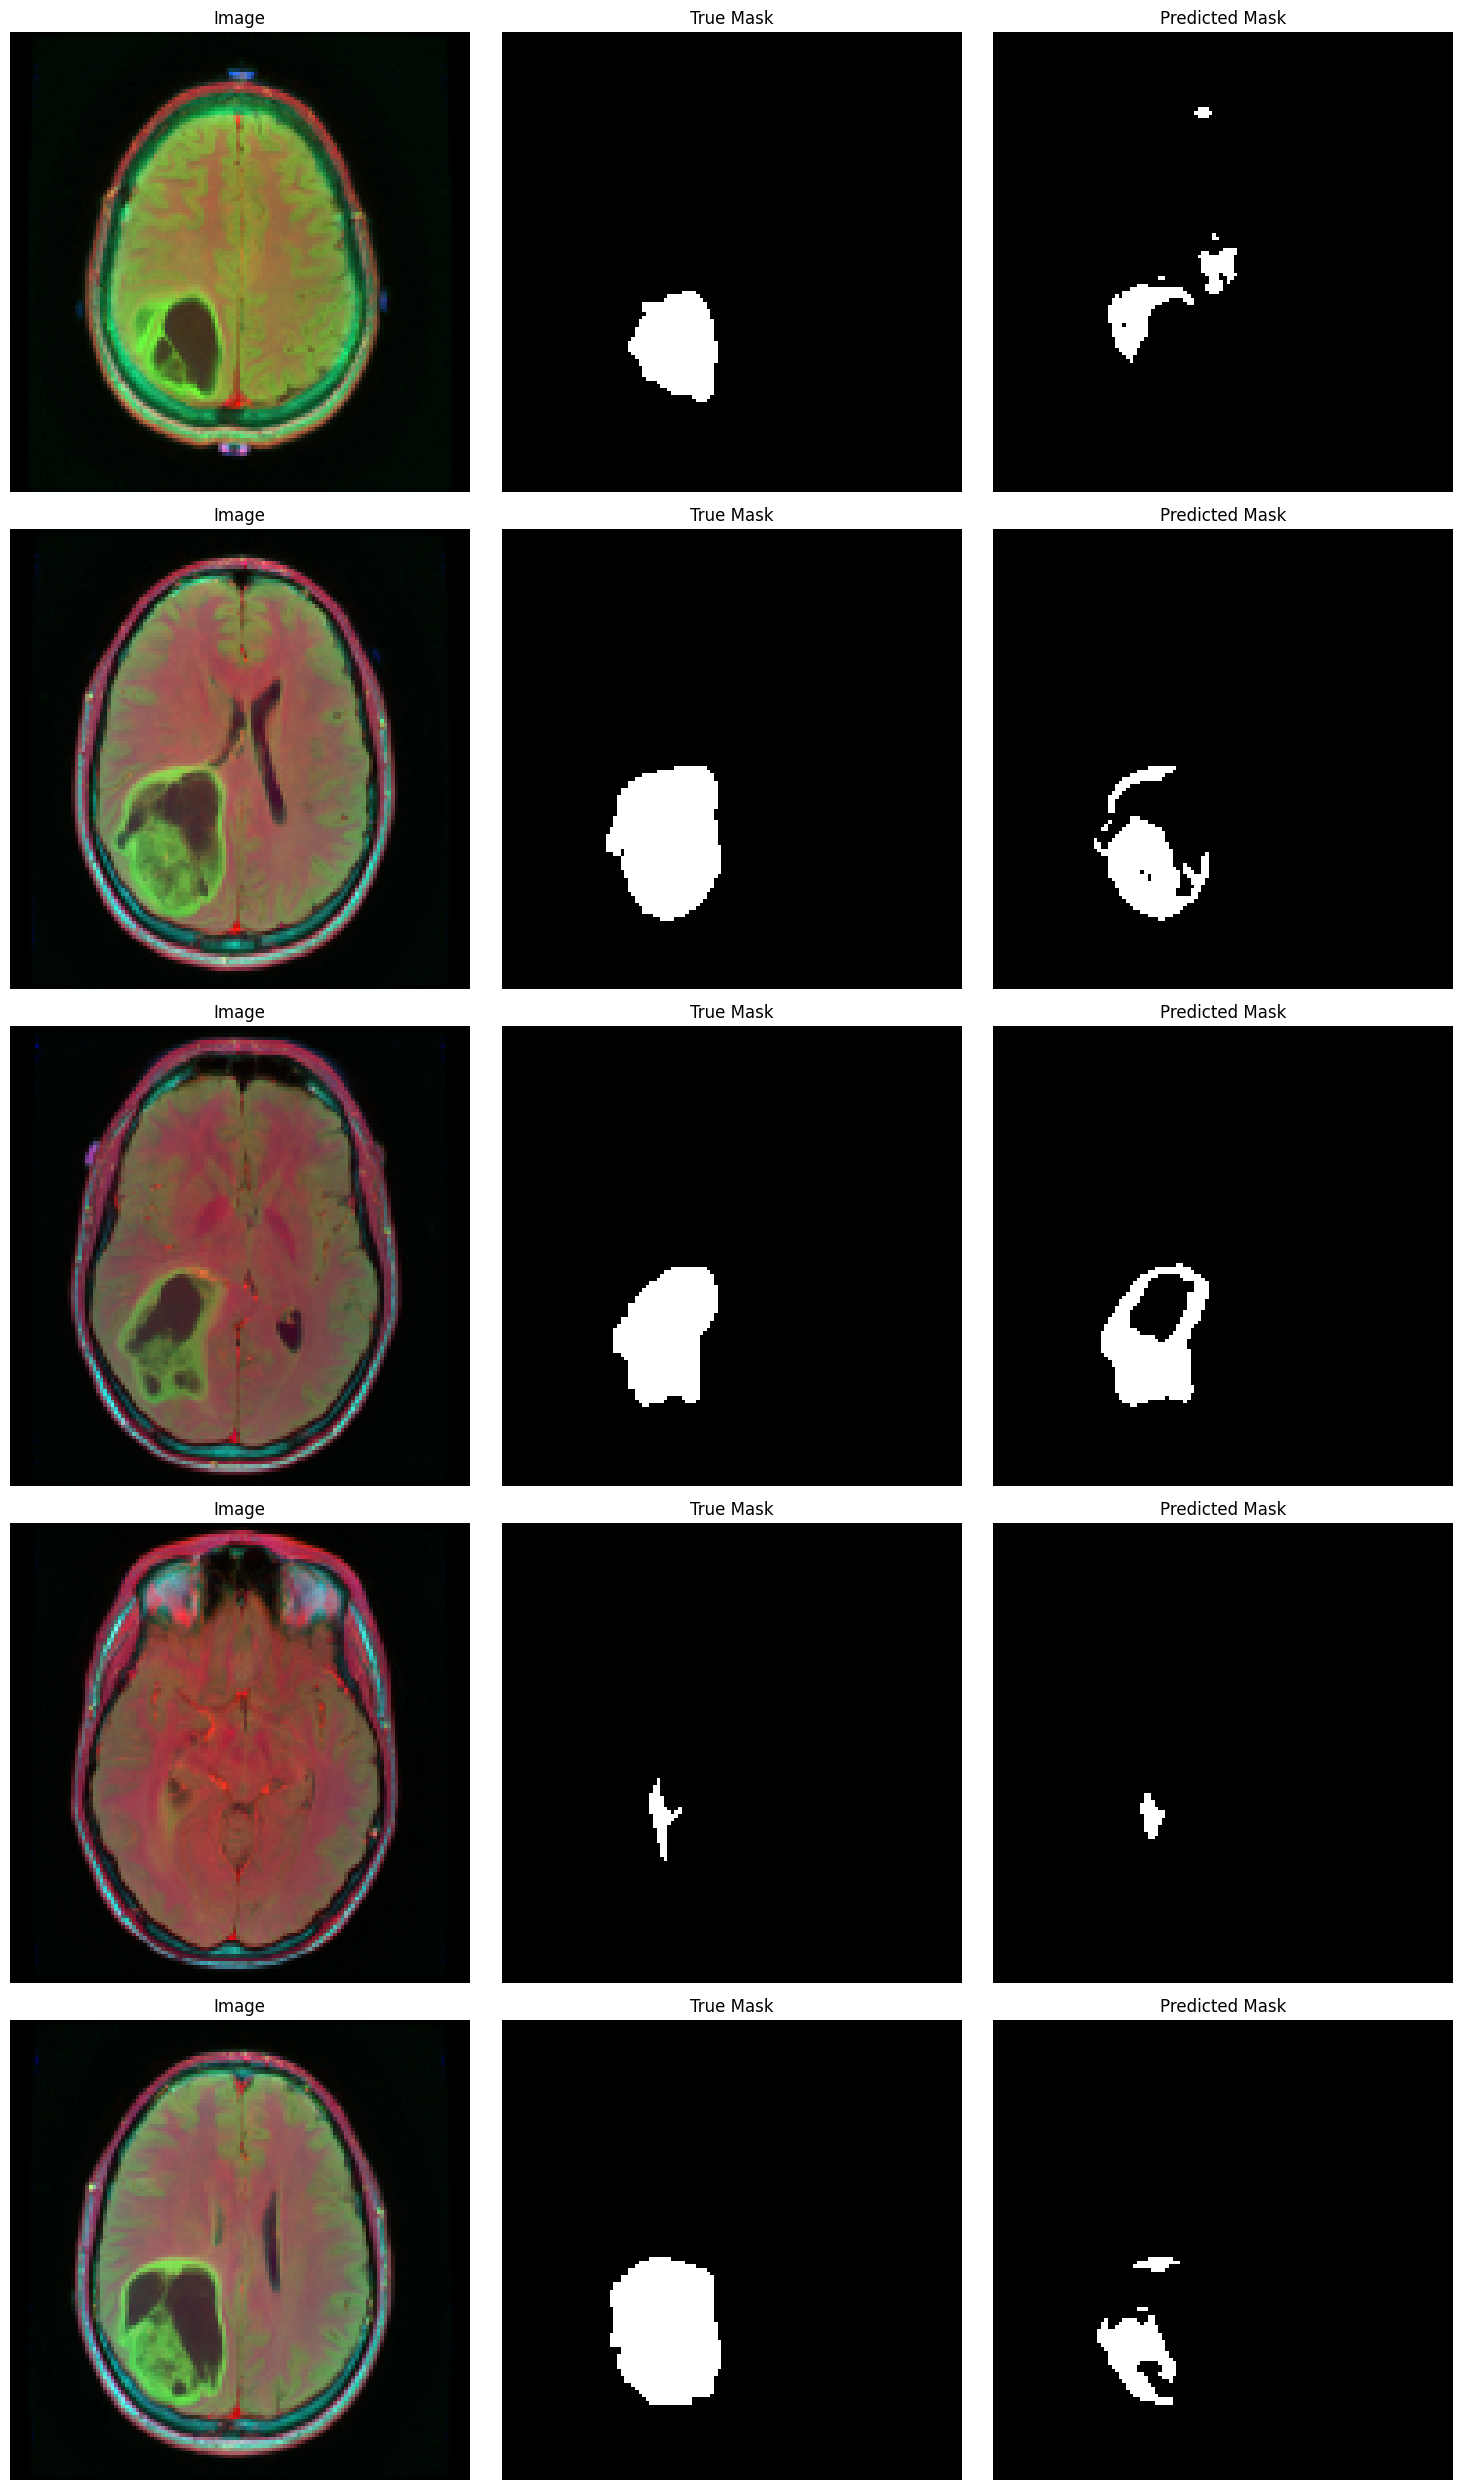

In [63]:
data_iter = iter(test_loader)

first_batch_img, first_batch_msk = next(data_iter)
second_batch_img, second_batch_msk = next(data_iter)
third_batch_img, third_batch_msk = next(data_iter)

images = third_batch_img.to(device)
masks = third_batch_msk.unsqueeze(1).to(device)

with torch.no_grad():
    masks_pred = model_unet(images.float())
    masks_pred = (masks_pred > 0.5).float()

random_indices = np.random.choice(images.size(0), 5, replace=False)

#Plot the images, true masks, and predicted masks
num = 5
fig, axes = plt.subplots(num, 3, figsize=(15, num * 5))

for i, idx in enumerate(random_indices):
    img = images[idx].cpu().numpy().transpose(1, 2, 0)  # Convert to HWC format for plotting
    true_mask = masks[idx][0].cpu().numpy()  # Convert to HxW format
    pred_mask = masks_pred[idx][0].cpu().numpy().astype(np.uint8)  # Convert to HxW format

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Image")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(true_mask, cmap='gray')
    axes[i, 1].set_title("True Mask")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_mask, cmap='gray')
    axes[i, 2].set_title("Predicted Mask")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()
